## Sorter comparison

Chosing a sorter is very hard...

Here some example how to compare sorter.

The idea is simple count how many spikes at the same time (with small tolerance lag) we have on each pairs.



In [1]:
import json
import warnings
from pathlib import Path

import spikeinterface.full as si


In [2]:


# change this path to point to the folder your data is in
# base_folder = Path("/home/samuel/Documents/DataSpikeSorting/school_neuralnet_2026/")
base_folder = Path("/mnt/data/sam/DataSpikeSorting/school_neuralnet_2026/")
# base_folder = Path("/home/pierre/school_neuralnet_2026/")

data_folder = base_folder / "data"
name = "sub-A3702_ses-191126-3600s"
result_folder = base_folder / "results" / name
result_folder.mkdir(exist_ok=True)


In [3]:
# sorter_name1 = "lupin"
sorter_name1 = "kilosort4"
# sorter_name1 = "dartsort"
analyzer_folder1 = result_folder / f"analyzer_{sorter_name1}"

sorting1 = si.load(analyzer_folder1).sorting
sorting1

NumpySorting: 174 units - 1 segments - 20.0kHz

In [4]:
# sorter_name2 = "lupin"
# sorter_name2 = "kilosort4"
sorter_name2 = "dartsort"
analyzer_folder2 = result_folder / f"analyzer_{sorter_name2}"

sorting2 = si.load(analyzer_folder2).sorting
sorting2

NumpySorting: 393 units - 1 segments - 20.0kHz

In [5]:
comp = si.compare_two_sorters(sorting1=sorting1, sorting2=sorting2, sorting1_name=sorter_name1, sorting2_name=sorter_name2)
comp

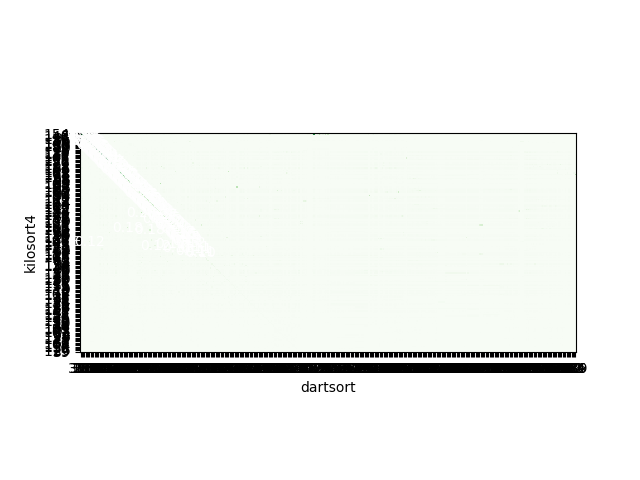

In [6]:
%matplotlib widget
si.plot_agreement_matrix(comp)

## compare multiple sorters

In [ ]:

names = ["lupin", "kilosort4", "dartsort"]
sortings = [si.load(result_folder / f"analyzer_{name}").sorting for name in names]

comp = si.compare_multiple_sorters(sortings, names,
                                   delta_time=0.4,
                                   match_score=0.5,
                                    do_matching=False)
# trick to be faster
comp._compute_all()



In [14]:
comp

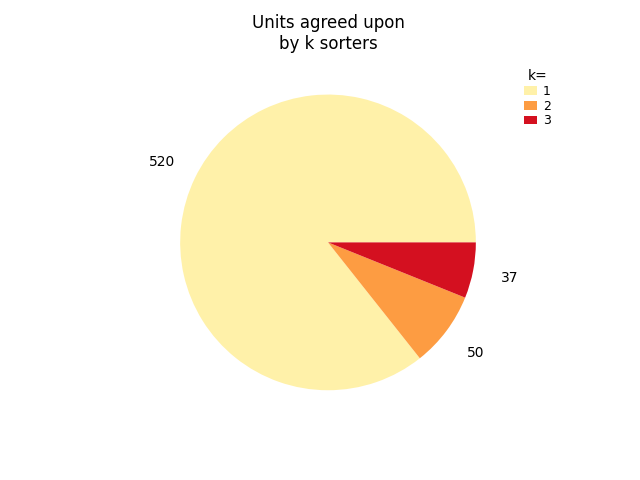

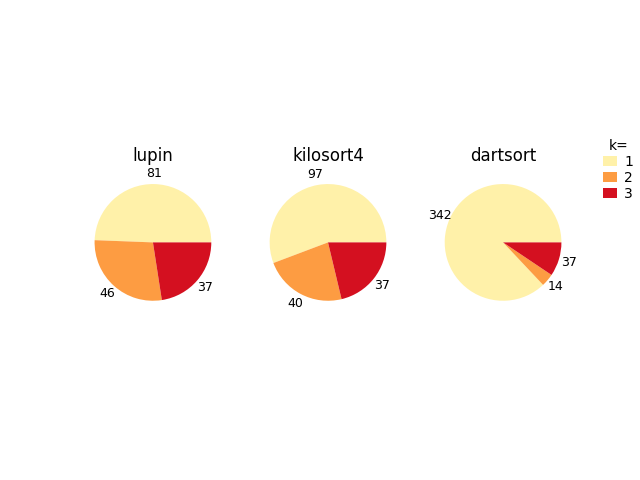

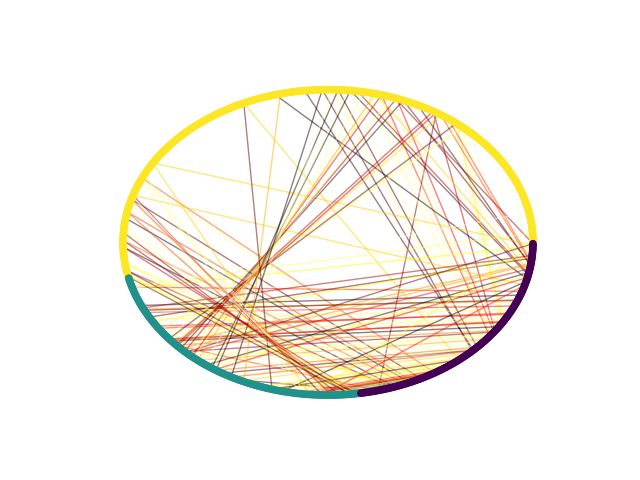

In [16]:
si.plot_multicomparison_agreement(comp)
si.plot_multicomparison_agreement_by_sorter(comp)
si.plot_multicomparison_graph(comp)
